In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
video_path = 'vtest.avi'
cap = cv2.VideoCapture(video_path)
n_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)
n_frames, w, h, fps

(795, 768, 576, 10.0)

In [3]:
zone = np.int32([[0, 380], [380, 380], [380, 576], [0, 576]])
warmup = 30
subtractor = cv2.createBackgroundSubtractorMOG2(history=200, varThreshold=50, detectShadows=True)
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))


def process(frame, learning):
    mask = subtractor.apply(frame)
    mask = cv2.threshold(mask, 200, 255, cv2.THRESH_BINARY)[1]
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.dilate(mask, kernel, iterations=2)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

    out = frame.copy()
    alarm = False
    for c in contours:
        if cv2.contourArea(c) < 800:
            continue
        x, y, bw, bh = cv2.boundingRect(c)
        feet = (x + bw // 2, y + bh)
        inside = cv2.pointPolygonTest(zone, feet, False) >= 0
        alarm = alarm or (inside and not learning)
        cv2.rectangle(out, (x, y), (x + bw, y + bh), (0, 0, 255) if inside else (0, 255, 0), 2)
    cv2.polylines(out, [zone], True, (0, 0, 255) if alarm else (255, 255, 0), 3)
    if alarm:
        cv2.putText(out, 'ALARM', (20, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.5, (0, 0, 255), 4)
    return out, alarm

In [4]:
os.makedirs('output', exist_ok=True)
writer = cv2.VideoWriter('output/task8_alarm.mp4', cv2.VideoWriter_fourcc(*'mp4v'), fps, (w, h))

alarm_frames = []
samples = {}
i = 0
while True:
    ok, frame = cap.read()
    if not ok:
        break
    out, alarm = process(frame, i < warmup)
    writer.write(out)
    if alarm:
        alarm_frames.append(i)
    if i % 5 == 0:
        samples[i] = (out, alarm)
    i += 1
cap.release()
writer.release()

print('frames:', i, 'alarm frames:', len(alarm_frames))
print('first alarm at frame', alarm_frames[0] if alarm_frames else None)

frames: 795 alarm frames: 159
first alarm at frame 530


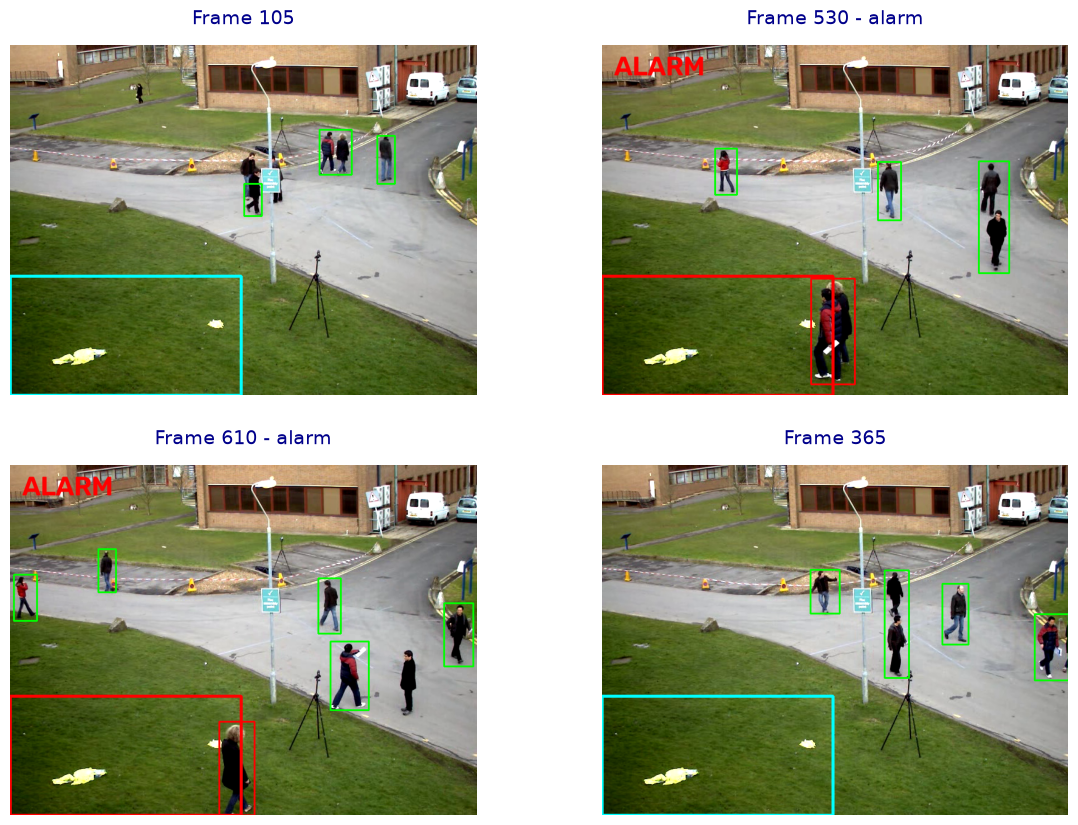

In [5]:
quiet = [k for k in samples if not samples[k][1] and k > 100]
loud = [k for k in samples if samples[k][1]]
pick = [quiet[0], loud[0], loud[len(loud) // 2], quiet[len(quiet) // 2]]
panels = [(f'Frame {k}' + (' - alarm' if samples[k][1] else ''), cv2.cvtColor(samples[k][0], cv2.COLOR_BGR2RGB)) for k in pick]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (title, im) in zip(axes, panels):
    ax.imshow(im)
    ax.axis('off')
    ax.set_title(title, fontsize=14, color='darkblue', pad=15)

plt.show()

In [6]:
cv2.imwrite('output/task8_alarm.png', samples[loud[0]][0])

True

MOG2 background subtraction, shadows removed by thresholding at 200, then opening and dilation. Contours under 800 px are ignored. A person is inside the zone (bottom left lawn) when the bottom centre of their box is in it, and then the zone turns red with ALARM.

The first 30 frames only learn the background, without this the first frames counted as moving. Alarm was on in 159 of 795 frames, first at frame 530. People on the path stay green. Two people close together can end up in one box.